# Diabetes Progression Prediction using Multiple Linear Regression

## Introduction
In this notebook, a multiple linear regression model is built to predict diabetes progression based on several health-related variables. The dataset contains medical measurements such as age, BMI, blood pressure, and cholesterol levels.

The goal of this analysis is to:
- Separate independent and dependent variables
- Train a regression model
- Evaluate the model using R²
- Interpret the impact of variables on diabetes progression

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import r2_score

## Loading the Dataset

The diabetes_dirty.csv dataset contains several health indicators that may influence diabetes progression. The dataset is loaded into a pandas DataFrame for analysis.

In [2]:

df = pd.read_csv("diabetes_dirty.csv")

df.head()

,AGE,SEX,BMI,BP,S1,S2,S3,S4,S5,S6,PROGRESSION
0,59,2,32.1,101.0,157,93.2,38.0,4.0,4.8598,87,151
1,48,1,21.6,87.0,183,103.2,70.0,3.0,3.8918,69,75
2,72,2,30.5,93.0,156,93.6,41.0,4.0,4.6728,85,141
3,24,1,25.3,84.0,198,131.4,40.0,5.0,4.8903,89,206
4,50,1,23.0,101.0,192,125.4,52.0,4.0,4.2905,80,135


## Inspecting Dataset Structure

Understanding the dataset structure helps identify data types, missing values, and possible cleaning requirements.

In [14]:
# Dataset information
df.info()

# Summary statistics
df.describe()

# Check missing values
df.isnull().sum()

# Remove duplicate rows if any
df = df.drop_duplicates()
df.columns

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   AGE          442 non-null    int64  
 1   SEX          442 non-null    int64  
 2   BMI          442 non-null    float64
 3   BP           442 non-null    float64
 4   S1           442 non-null    int64  
 5   S2           442 non-null    float64
 6   S3           442 non-null    float64
 7   S4           442 non-null    float64
 8   S5           442 non-null    float64
 9   S6           442 non-null    int64  
 10  PROGRESSION  442 non-null    int64  
dtypes: float64(6), int64(5)
memory usage: 38.1 KB


Index(['AGE', 'SEX', 'BMI', 'BP', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6',
       'PROGRESSION'],
      dtype='str')

## Identifying Independent and Dependent Variables

The dependent variable represents diabetes progression.  
All other variables act as independent variables used to predict the outcome

In [15]:
# Independent variables (features)
X = df.drop(columns=["PROGRESSION"])

# Dependent variable (target)
y = df["PROGRESSION"]

## Splitting Data into Training and Test Sets

The dataset is split into training and testing sets using an 80/20 ratio.

Training data is used to train the model, while testing data evaluates the model's ability to make predictions on unseen data.

In [16]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Feature Scaling

Scaling ensures that all variables contribute equally to the regression model. Two scaling methods are explored:

- StandardScaler
- MinMaxScaler

For this model, StandardScaler is applied.

In [17]:
# Apply StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Training the Multiple Linear Regression Model

The LinearRegression model from sklearn is used to fit the training data.  
This model estimates how each independent variable influences diabetes progression.

In [18]:
# Train regression model
model = LinearRegression()

model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## Model Coefficients and Intercept

The intercept represents the predicted value when all independent variables are zero.

The coefficients indicate how much the dependent variable changes when each feature increases by one unit.

In [19]:

# Print model parameters
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: 153.7365439093484
Coefficients: [  1.75375799 -11.51180908  25.60712144  16.82887167 -44.44885564
  24.64095356   7.67697768  13.1387839   35.16119521   2.35136365]


## Making Predictions

The trained model is used to generate predictions on the test dataset.

In [20]:
# Generate predictions
y_pred = model.predict(X_test_scaled)

## Evaluating Model Performance

The R² score measures how well the regression model explains variation in the target variable.

An R² value closer to 1 indicates a better fit.

In [21]:
# Calculate R2 score
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.45260276297191915


## Visualising Predictions vs Actual Values

A scatter plot is used to compare predicted values with actual diabetes progression values.

If the model performs well, points should align closely with the regression line.

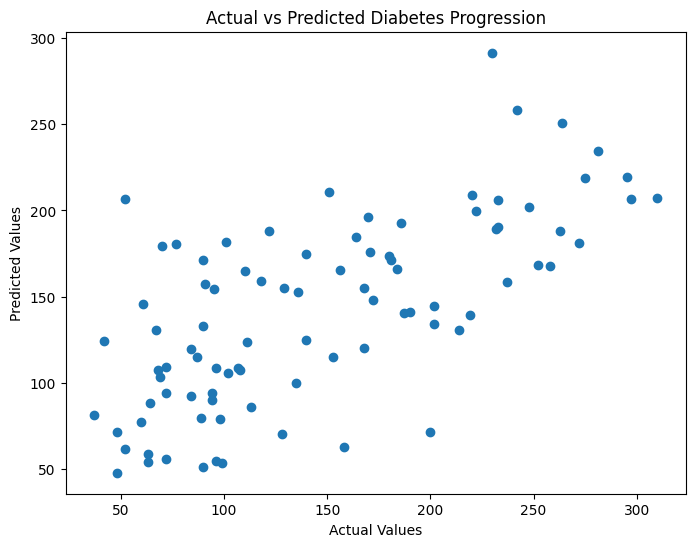

In [22]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Diabetes Progression")

plt.show()

## Conclusion

A multiple linear regression model was successfully trained to predict diabetes progression using several health indicators.

The model coefficients show how each variable contributes to the prediction.  
The R² score provides insight into how well the model explains the variation in diabetes progression.

Further improvements could involve additional feature engineering, removing outliers, or testing other machine learning models.